# Day 2 — from LSS observables to Fisher forecasts
**Prerequisites:** Day 1's Bayesian toy notebook. **Kernel:** `lecture`.

We will compute Euclid-like 3×2pt and spectroscopic forecasts, fix versus marginalise nuisance parameters, add a prior, and compare with archived Boltzmann-code forecasts and MontePython samples.

**Live route (15 min):** §§1–3; show the pre-run outputs in §§4–6. The symbolic power-spectrum backend is fast but approximate. These are forecasts of mock observations, not measurements of the real Universe.

Sources: Casas et al., [2303.09451v1](https://arxiv.org/abs/2303.09451v1); Euclid Collaboration, [2405.06047v1](https://arxiv.org/abs/2405.06047v1). File provenance is in `data/manifest.json`.


In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['OPENBLAS_NUM_THREADS'] = '1'
from pathlib import Path
from time import perf_counter
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from scipy.stats import chi2
from cosmicfishpie.fishermatrix.cosmicfish import FisherMatrix
from cosmicfishpie.analysis import fisher_matrix as fm, fisher_operations as ops

from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / 'data').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
assert (ROOT / 'data').is_dir(), 'run this notebook from inside the bayes-cosmo-course repository'
DATA = ROOT / 'data'
OUTPUT = ROOT / 'output'
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.size': 12, 'figure.dpi': 110})
timings = {}

## 1. A live 3×2pt forecast
The combined vector contains shear–shear, galaxy–galaxy and galaxy–shear spectra. `['WL','GCph']` already includes the cross-correlation.

Use the **same seven cosmological parameters** for both probes before combining them: $\Omega_m,\Omega_b,h,n_s,\sigma_8,w_0,w_a$. Nuisance parameters are added by the code. The derivative values are fractional steps (with a special absolute step at a zero fiducial), not prior widths.

The `Paper` survey YAMLs follow the 2024 setup; the 2023 optimistic GCph cut was 1500, whereas the 2024 cut is 3000. This live run is a teaching configuration, not an exact rerun of either paper.


In [2]:
fiducial = dict(Omegam=.32, Omegab=.05, h=.67, ns=.96, sigma8=.815584,
                w0=-1., wa=0., mnu=.06)
cosmo_names = ['Omegam', 'Omegab', 'h', 'ns', 'sigma8', 'w0', 'wa']

def forecast(probe='photo', scenario='Pessimistic'):
    options = dict(feedback=0, code='symbolic', cosmo_model='w0waCDM',
        accuracy=1, derivatives='3PT', nonlinear=True, ell_sampling=25,
        survey_name='Euclid', fail_on_specs_not_found=True,
        survey_name_photo=f'Euclid-Photometric-Paper-{scenario}',
        survey_name_spectro=f'Euclid-Spectroscopic-Paper-{scenario}',
        outroot=f'lecture_{probe}_{scenario}', results_dir=str(OUTPUT) + '/')
    start = perf_counter()
    model = FisherMatrix(options=options, fiducialpars=fiducial.copy(),
        freepars={p: .01 for p in cosmo_names},
        observables=['WL', 'GCph'] if probe == 'photo' else ['GCsp'],
        cosmoModel='w0waCDM', surveyName='Euclid')
    result = model.compute()
    timings[f'{probe}_{scenario}'] = perf_counter() - start
    result.name = f'{probe} {scenario}'
    print(result.name, 'parameters:', result.get_param_names())
    print('Seconds:', round(timings[f'{probe}_{scenario}'], 2))
    return result

photo = forecast()



  Fisher matrix exported: /home/santiago/CosmoProjects/bayes-cosmo-course/output//CosmicFish_v1.3.1_lecture_photo_Pessimistic_WLGCph_FM.txt

photo Pessimistic parameters: ['Omegam', 'Omegab', 'h', 'ns', 'sigma8', 'w0', 'wa', 'b1', 'b2', 'b3', 'b4', 'b5', 'b6', 'b7', 'b8', 'b9', 'b10', 'AIA', 'etaIA']
Seconds: 8.05


fatal: ambiguous argument 'HEAD': unknown revision or path not in the working tree.
Use '--' to separate paths from revisions, like this:
'git <command> [<revision>...] -- [<file>...]'
fatal: ambiguous argument 'HEAD': unknown revision or path not in the working tree.
Use '--' to separate paths from revisions, like this:
'git <command> [<revision>...] -- [<file>...]'


In [3]:
photo_opt = forecast(scenario='Optimistic')
spectro = forecast('spectro')
# Independent-probe approximation: neglect photo–spectro cross-covariance.
combined = photo + spectro
combined.name = '3x2pt + GCsp'



  Fisher matrix exported: output//CosmicFish_v1.3.1_lecture_photo_Optimistic_WLGCph_FM.txt

photo Optimistic parameters: ['Omegam', 'Omegab', 'h', 'ns', 'sigma8', 'w0', 'wa', 'b1', 'b2', 'b3', 'b4', 'b5', 'b6', 'b7', 'b8', 'b9', 'b10', 'AIA', 'etaIA']
Seconds: 7.72
Computing derivatives of Galaxy Clustering Spectro
>> Computing Derivs >>



  Fisher matrix exported: output//CosmicFish_v1.3.1_lecture_spectro_Pessimistic_GCsp_FM.txt

spectro Pessimistic parameters: ['Omegam', 'Omegab', 'h', 'ns', 'sigma8', 'w0', 'wa', 'lnbg_1', 'lnbg_2', 'lnbg_3', 'lnbg_4', 'Ps_1', 'Ps_2', 'Ps_3', 'Ps_4']
Seconds: 3.09


## 2. Marginalising is not fixing
Partition $F=\begin{pmatrix}A&B\\B^T&D\end{pmatrix}$ into parameters of interest and nuisance parameters.

* Fix nuisance parameters: $F_{\rm fixed}=A$.
* Integrate them out (Gaussian approximation): $F_{\rm marg}=A-BD^{-1}B^T$.
* Equivalently invert $F$, keep the desired covariance block, then invert it.

Every other cosmological parameter is also marginalised in the plots below. A 68.3% **joint 2D** contour uses $\Delta\chi^2=2.30$, not 1.


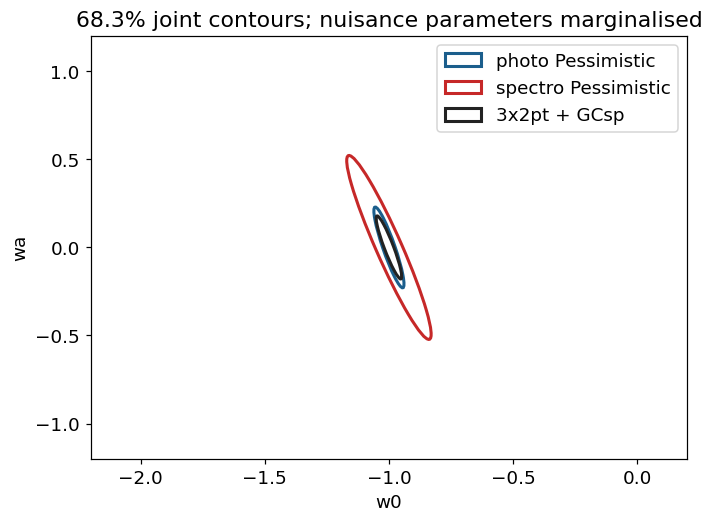

,FoM
photo Pessimistic,3.912062272E+02
photo Optimistic,1.783716565E+03
spectro Pessimistic,7.815283076E+01
3x2pt + GCsp,6.473745509E+02


In [4]:
def ellipse(ax, fisher, names, color, label, fixed=False):
    reduced = (ops.reshuffle if fixed else ops.marginalise)(fisher, names, update_names=False)
    covariance = reduced.get_fisher_inverse()
    vals, vecs = np.linalg.eigh(covariance)
    angle = np.degrees(np.arctan2(vecs[1, 1], vecs[0, 1]))
    widths = 2 * np.sqrt(chi2.ppf(.683, 2) * vals)
    center = reduced.get_param_fiducial()
    ax.add_patch(Ellipse(center, widths[1], widths[0], angle=angle,
                         fill=False, lw=2, color=color, label=label))
    ax.update_datalim([center - widths.max(), center + widths.max()])
    ax.autoscale_view()
    ax.set(xlabel=names[0], ylabel=names[1])

def fom(fisher):
    reduced = ops.marginalise(fisher, ['w0', 'wa'], update_names=False)
    return np.sqrt(np.linalg.det(reduced.fisher_matrix))

fig, ax = plt.subplots(figsize=(7, 5))
for f, color in [(photo, '#1B5E8C'), (spectro, '#C62828'), (combined, '#222222')]:
    ellipse(ax, f, ['w0', 'wa'], color, f.name)
ax.legend(); ax.set_title('68.3% joint contours; nuisance parameters marginalised')
fig.savefig(OUTPUT / 'probe_complementarity.png', bbox_inches='tight')
plt.show()
pd.DataFrame({'FoM': {f.name: fom(f) for f in [photo, photo_opt, spectro, combined]}})


In [5]:
names = ['w0', 'wa']
fixed = ops.reshuffle(photo, names, update_names=False)
marg = ops.marginalise(photo, names, update_names=False)
pd.DataFrame({'fixed_all_others': np.sqrt(np.diag(fixed.get_fisher_inverse())),
              'marginalised': np.sqrt(np.diag(marg.get_fisher_inverse()))}, index=names)


,fixed_all_others,marginalised
w0,7.610730384E-03,4.005050957E-02
wa,3.570912733E-02,1.511545910E-01


## 3. Add a prior before inverting
An independent Gaussian prior on $h$ with width 0.01 contributes $F_{hh}^{\rm prior}=1/0.01^2$. This is an **illustrative scalar prior**, not a Planck likelihood. A real CMB prior is correlated and must use matching parameters and fiducials.


In [6]:
prior = fm.fisher_matrix(fisher_matrix=np.array([[1/.01**2]]), param_names=['h'],
    param_names_latex=['h'], fiducial=np.array([.67]), name='illustrative h prior')
with_prior = photo + prior
print('FoM without / with prior:', fom(photo), fom(with_prior))
assert fom(with_prior) >= fom(photo)


FoM without / with prior: 391.20622717404456 509.360554313175


## 4. Baseline-model validation: archived high-precision runs
Load the local October 2026 CAMB/CLASS reruns with the 2023 baseline fiducial. These are **archived reruns**, not the published matrices themselves. Compare the errors with the published rounded values (2303.09451, Table 8); inspect the bundled `_specs.json` before interpreting differences.


In [7]:
archive = {f'{p}_{c}': fm.fisher_matrix(file_name=str(DATA / 'baseline' / f'{p}_{c}.txt'))
           for p in ['photo', 'spectro'] for c in ['camb', 'class']}
names = ['Omegab', 'h', 'ns', 'sigma8', 'Omegam', 'w0', 'wa']
def sigmas(f, names):
    reduced = ops.marginalise(f, names, update_names=False)
    return np.sqrt(np.diag(reduced.get_fisher_inverse()))
table = pd.DataFrame({key: sigmas(value, names) for key, value in archive.items()}, index=names)
table['paper_photo_CF'] = [.0027, .020, .010, .0041, .0036, .043, .17]
table['paper_photo_MCMC'] = [.0026, .021, .011, .0044, .0038, .045, .18]
table['photo_CAMB_CLASS_percent'] = 100*(table.photo_camb/table.photo_class - 1)
display(table)
table.to_csv(OUTPUT / 'baseline_comparison.csv')


,photo_camb,photo_class,spectro_camb,spectro_class,paper_photo_CF,paper_photo_MCMC,photo_CAMB_CLASS_percent
Omegab,2.633750395E-03,2.653872626E-03,2.405595098E-03,2.414114913E-03,2.700000000E-03,2.600000000E-03,-7.582214394E-01
h,2.038900087E-02,2.045557708E-02,2.004379607E-02,2.004971932E-02,2.000000000E-02,2.100000000E-02,-3.254672756E-01
ns,1.021220678E-02,1.019776579E-02,1.419306314E-02,1.419141948E-02,1.000000000E-02,1.100000000E-02,1.416093352E-01
sigma8,4.085327869E-03,4.084924341E-03,1.542218341E-02,1.545089035E-02,4.100000000E-03,4.400000000E-03,9.878458287E-03
Omegam,3.553375351E-03,3.552727570E-03,1.605311216E-02,1.607845399E-02,3.600000000E-03,3.800000000E-03,1.823333842E-02
w0,4.251108425E-02,4.250632293E-02,1.370246532E-01,1.373028407E-01,4.300000000E-02,4.500000000E-02,1.120144928E-02
wa,1.735683694E-01,1.734620939E-01,4.084426829E-01,4.093929540E-01,1.700000000E-01,1.800000000E-01,6.126728272E-02


### A real MontePython posterior
The bundled samples are from `w0wa_photo_pess`: seven cosmological parameters plus marginalised nuisances. Multiplicity weights are preserved; the first 30% of stored rows of each chain were discarded. This is a pedagogical overlay with the modern rerun, not a fresh convergence certification. The published matched-pipeline comparison is shown in the slides.


Removed no burn in


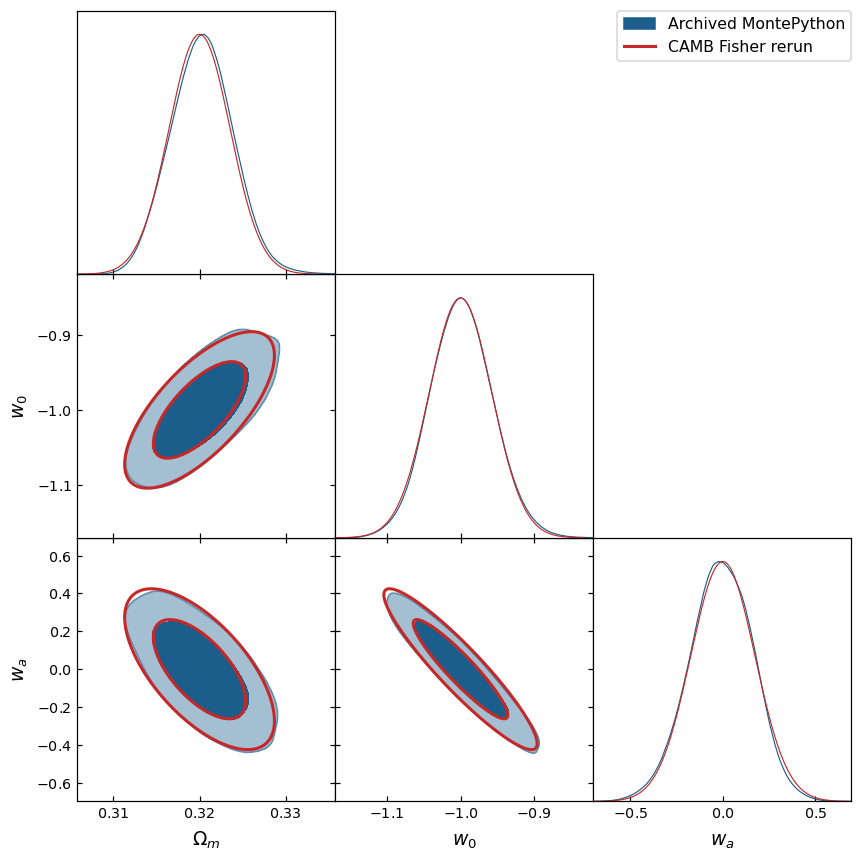

In [8]:
from getdist import MCSamples, plots
from getdist.gaussian_mixtures import GaussianND
stored = np.load(DATA / 'baseline/montepython_samples.npz')
a = stored['samples']
samples = MCSamples(samples=a[:, 2:], weights=a[:, 0], loglikes=a[:, 1],
    names=names, labels=[r'\Omega_b', 'h', 'n_s', r'\sigma_8', r'\Omega_m', 'w_0', 'w_a'],
    settings={'ignore_rows': 0})
f = ops.marginalise(archive['photo_camb'], names, update_names=False)
gaussian = GaussianND(f.get_param_fiducial(), f.get_fisher_inverse(), names=names)
g = plots.get_subplot_plotter(width_inch=8)
g.triangle_plot([samples, gaussian], ['Omegam', 'w0', 'wa'],
                filled=[True, False], legend_labels=['Archived MontePython', 'CAMB Fisher rerun'],
                colors=['#1B5E8C', '#C62828'], contour_colors=['#1B5E8C', '#C62828'], lws=[1.5, 2.0])
g.export(str(OUTPUT / 'baseline_montepython.png'))
plt.show()


## 5. Neutrinos: forecast errors versus a physical boundary
Load the 2024 **seven-parameter** $\Lambda$CDM+$M_\nu+N_{\rm eff}$ photometric pessimistic Fisher. The physical $M_\nu>0$ prior is not Gaussian and cannot be represented by simply adding a Fisher matrix.

The available local neutrino MCMC folder floats **nine** cosmological parameters (including $w_0,w_a$), unlike this validation case. We therefore show the **published matched-case MCMC comparison**, rather than overlaying an incompatible chain. Do not reproduce the final MCMC sensitivities (56/23/16 meV) using an unrestricted Gaussian ellipse.


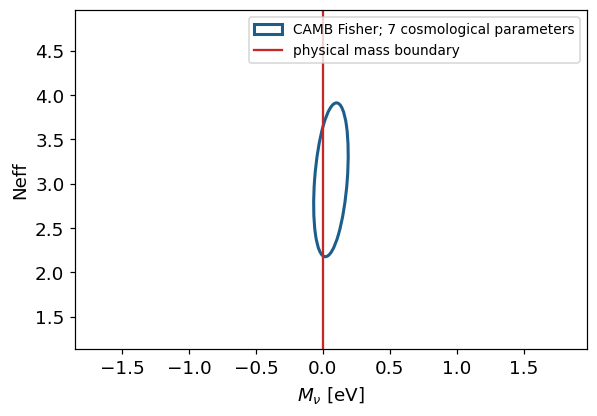

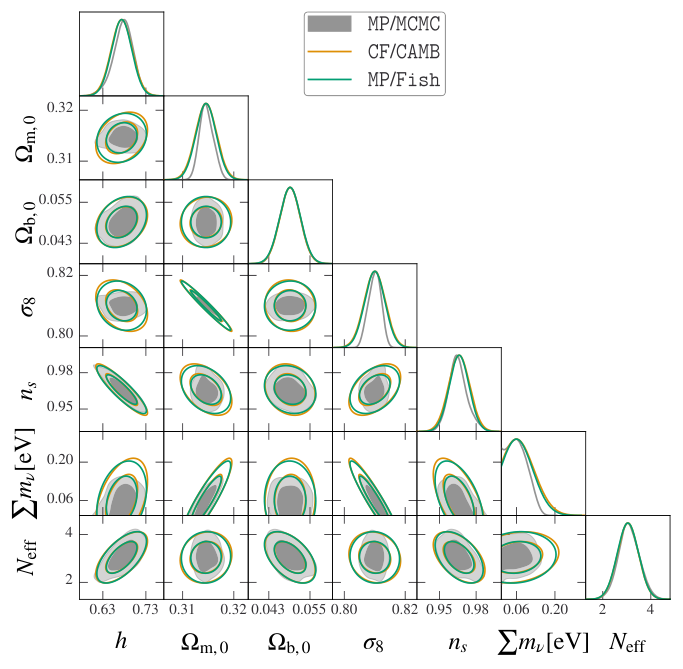

Credit: Euclid Collaboration, arXiv:2405.06047v1, Fig. 10 (photometric panel).


In [9]:
nu = fm.fisher_matrix(file_name=str(DATA / 'neutrino/cfp_camb.txt'))
fig, ax = plt.subplots(figsize=(6, 4))
ellipse(ax, nu, ['mnu', 'Neff'], '#1B5E8C', 'CAMB Fisher; 7 cosmological parameters')
ax.axvline(0, color='#C62828', label='physical mass boundary')
ax.set_xlabel(r'$M_\nu$ [eV]'); ax.legend(fontsize=9)
plt.show()
from IPython.display import Image, display
display(Image(filename=str(ROOT / 'data/figs/day2_neutrino.png'), width=700))
print('Credit: Euclid Collaboration, arXiv:2405.06047v1, Fig. 10 (photometric panel).')


## 6. Instructor's background Nautilus job
Optional: run the sampler yourself following `docs/nautilus.md`. It samples $(\Omega_m,\sigma_8,h)$ with fixed nuisance parameters. Nautilus is an importance nested sampler, not a Metropolis chain. Its weighted ESS has a different interpretation from MCMC autocorrelation ESS.

The cell below uses `LECTURE_NAUTILUS_DIR` if set; otherwise it shows the bundled local rehearsal. It always reads the job's own **conditional** reference Fisher. Use the job's metadata to check parameter names, priors and runtime.


{'free_params': ['Omegam', 'sigma8', 'h'], 'reference_kind': 'conditional', 'elapsed_seconds': 408.799973487854, 'effective_sample_size': 1195.855059306542}
Removed no burn in


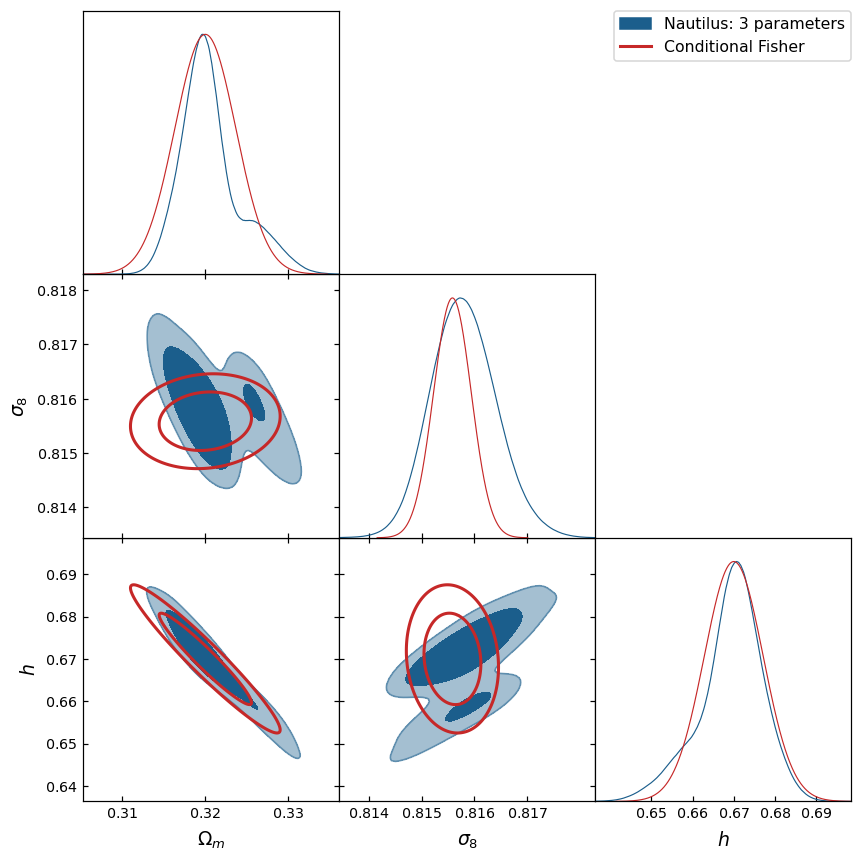

posterior std  (Nautilus): {'Omegam': 0.00372, 'sigma8': 0.00061, 'h': 0.00784}
posterior std  (Fisher)  : {'Omegam': 0.00368, 'sigma8': 0.00036, 'h': 0.00715}
corr(Om,s8), corr(s8,h) Nautilus: -0.51 0.59


In [10]:
run = Path(os.environ.get('LECTURE_NAUTILUS_DIR', str(DATA / 'nautilus/gcsp'))).expanduser()
meta = json.loads((run / 'case_metadata.json').read_text())
print({key: meta[key] for key in ['free_params', 'reference_kind', 'elapsed_seconds', 'effective_sample_size']})
chain = pd.read_csv(run / Path(meta['chain']).name)
reference = fm.fisher_matrix(file_name=str(run / Path(meta['fisher_reference']).name))
params = meta['sampled_parameters']
assert meta['reference_kind'] == 'conditional'
post = MCSamples(samples=chain[params].to_numpy(), weights=chain['weight'].to_numpy(),
                 names=params, labels=[r'\Omega_m', r'\sigma_8', 'h'])
ref = ops.reshuffle(reference, params, update_names=False)
normal = GaussianND(ref.get_param_fiducial(), ref.get_fisher_inverse(), names=params)
g = plots.get_subplot_plotter(width_inch=8)
g.triangle_plot([post, normal], params, filled=[True, False],
                legend_labels=['Nautilus: 3 parameters', 'Conditional Fisher'],
                colors=['#1B5E8C', '#C62828'], contour_colors=['#1B5E8C', '#C62828'], lws=[1.5, 2.0])
g.export(str(OUTPUT / 'nautilus_vs_fisher.png'))
plt.show()
sd = lambda c: np.sqrt(np.diag(c))
print('posterior std  (Nautilus):', dict(zip(params, np.round(sd(post.cov(params)), 5))))
print('posterior std  (Fisher)  :', dict(zip(params, np.round(sd(ref.get_fisher_inverse()), 5))))
print('corr(Om,s8), corr(s8,h) Nautilus:', np.round(post.corr(params)[0, 1], 2), np.round(post.corr(params)[1, 2], 2))

**Read this plot critically.** $\Omega_m$ and $h$ (and their degeneracy) agree between the sampler and the Fisher matrix. The $\sigma_8$ directions do **not**: the sampled posterior is wider in $\sigma_8$ and more correlated with $\Omega_m$ and $h$. We checked that this is not a sampler failure: a finite-difference Hessian of the very same `loglike` has cross terms $F_{\sigma_8 h}$ of opposite sign and much larger size than the first-derivative Fisher matrix. So the Fisher matrix and the likelihood differ in how the $\sigma_8$/bias-amplitude coupling is treated in this symbolic set-up, plus some emulator jitter. This is a good example for the class of why a Fisher forecast must be validated against the likelihood it is meant to approximate (as 2303.09451 does) -- and an item to follow up before quoting this case anywhere.

In [11]:
(OUTPUT / 'cfp_timings.json').write_text(json.dumps(timings, indent=2))


130

## Exercises
1. Predict what happens to the $w_0$–$w_a$ area when increasing $\ell_{\max}$. Compare `photo` and `photo_opt`. Why can modelling errors invalidate this statistical gain?
2. Change the illustrative $h$ prior to width 0.02. Does the FoM lie between the uninformative and 0.01-prior results?
3. Compare `ops.reshuffle` and `ops.marginalise` on the GCsp matrix. Which one is the right reference for the three-parameter Nautilus run? Then explain why $\sigma_8$ still disagrees (hint: finite-difference Hessian of `like.loglike`).
4. Optional workstation exercise: repeat a Fisher with half/double the derivative step, then replace symbolic by a matched high-precision CAMB profile. Compare *derivatives and marginalised errors*, not only $P(k)$.

**Answer scaffold:** a tighter independent prior cannot increase the Gaussian marginal covariance; a larger scale range adds information only under the assumed theory/covariance; fixed nuisance sampling requires the conditional Fisher. For the neutrino paper also match the tracer ($P_{cb}$ versus $P_m$), nonlinear model, neutrino convention, and physical priors.
